In [1]:
!pip install torch
!pip install torchtext==0.4.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 2.2 MB/s eta 0:00:00


#Part 1

In [27]:
from torchtext import data, datasets
import torch
# For tokenization
TEXT = data.Field(tokenize='spacy',
                  tokenizer_language='en_core_web_sm',
                  include_lengths = True)
# For multi-class classification labels
LABEL = data.LabelField()
# Load the TREC dataset
# train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)
train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)

In [28]:
TEXT.build_vocab(train_data,
                max_size=25000,
                vectors="glove.6B.100d",
                # min_freq=3,
                unk_init=torch.Tensor.normal_)
LABEL.build_vocab(train_data)

Using device: cuda

Vocab size: 9330
Classes: 6
Embedding dim: 100

TRAINING BiGRU
Epoch 01 | Train Loss: 0.691 Acc: 41.57% | Valid Loss: 0.474 Acc: 51.48%
Epoch 02 | Train Loss: 0.512 Acc: 54.98% | Valid Loss: 0.379 Acc: 58.21%
Epoch 03 | Train Loss: 0.423 Acc: 61.49% | Valid Loss: 0.369 Acc: 59.32%
Epoch 04 | Train Loss: 0.394 Acc: 66.22% | Valid Loss: 0.309 Acc: 71.15%
Epoch 05 | Train Loss: 0.337 Acc: 70.04% | Valid Loss: 0.295 Acc: 70.79%
Epoch 06 | Train Loss: 0.280 Acc: 75.12% | Valid Loss: 0.311 Acc: 78.53%
Epoch 07 | Train Loss: 0.261 Acc: 77.85% | Valid Loss: 0.266 Acc: 75.76%
Epoch 08 | Train Loss: 0.233 Acc: 79.63% | Valid Loss: 0.261 Acc: 75.85%
Epoch 09 | Train Loss: 0.201 Acc: 82.44% | Valid Loss: 0.217 Acc: 80.43%
Epoch 10 | Train Loss: 0.172 Acc: 84.09% | Valid Loss: 0.262 Acc: 84.07%
Epoch 11 | Train Loss: 0.168 Acc: 84.90% | Valid Loss: 0.272 Acc: 85.07%
Epoch 12 | Train Loss: 0.136 Acc: 88.39% | Valid Loss: 0.280 Acc: 86.39%
Epoch 13 | Train Loss: 0.138 Acc: 88.14% 

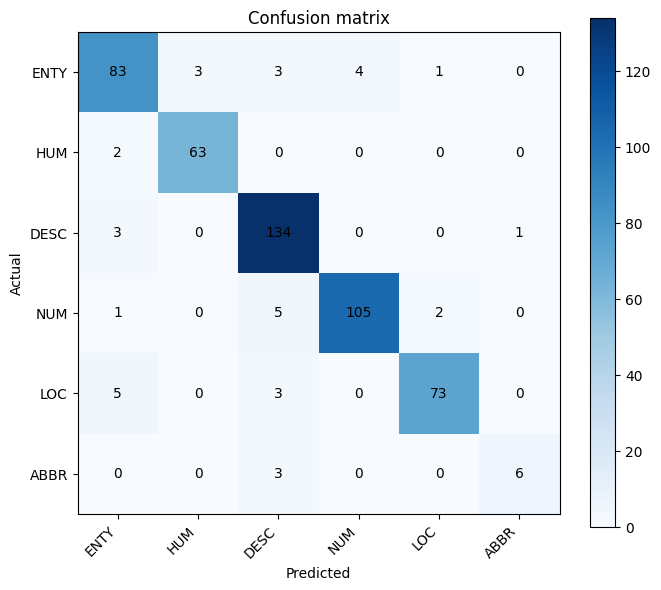

In [29]:
# ============================================================================
# PART 3(d): BiGRU with class weighting strategy and early stopping
# ============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchtext import data
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}\n')

# Config
BATCH_SIZE = 64
N_EPOCHS = 30
LEARNING_RATE = 1e-3
HIDDEN_DIM = 256
N_LAYERS = 2
DROPOUT = 0.5
GRAD_CLIP = 1.0
PATIENCE = 5

# split train and validation data
train_data, valid_data = train_data.split(split_ratio=0.85, random_state=random.seed(42))

# Create iterators
train_iterator, valid_iterator, test_iterator = data.BucketIterator.splits(
    (train_data, valid_data, test_data),
    batch_size=BATCH_SIZE,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text),
    device=device
)

# Get embeddings
vocab_size = len(TEXT.vocab)
output_size = len(LABEL.vocab)
embedding_dim = TEXT.vocab.vectors.size(1)
pretrained_embeddings = TEXT.vocab.vectors
PAD_IDX = TEXT.vocab.stoi[TEXT.pad_token]
UNK_IDX = TEXT.vocab.stoi[TEXT.unk_token]

print(f"Vocab size: {vocab_size}")
print(f"Classes: {output_size}")
print(f"Embedding dim: {embedding_dim}\n")

# Helper functions
def categorical_accuracy(preds, y):
    top_pred = preds.argmax(1)
    correct = top_pred.eq(y).sum().item()
    return correct / y.size(0)

def train_epoch(model, iterator, optimizer, criterion):
    model.train()
    epoch_loss = 0
    epoch_acc = 0

    for batch in iterator:
        text, text_lengths = batch.text
        if text.dim() == 2 and text.size(0) != text_lengths.size(0):
            text = text.transpose(0, 1)
        labels = batch.label.long().to(device)

        optimizer.zero_grad()
        predictions = model(text, text_lengths)
        loss = criterion(predictions, labels)
        acc = categorical_accuracy(predictions, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in iterator:
            text, text_lengths = batch.text
            if text.dim() == 2 and text.size(0) != text_lengths.size(0):
                text = text.transpose(0, 1)
            labels = batch.label.long().to(device)

            predictions = model(text, text_lengths)
            loss = criterion(predictions, labels)
            acc = categorical_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc
            all_preds.extend(predictions.argmax(1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return epoch_loss / len(iterator), epoch_acc / len(iterator), all_preds, all_labels # Return predictions and labels

# ============================================================================
# BiGRU MODEL
# ============================================================================
print("="*80)
print("TRAINING BiGRU")
print("="*80)

class BiGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, bidirectional, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(embedding_dim, hidden_dim, num_layers=n_layers, bidirectional=bidirectional,
                         dropout=dropout if n_layers > 1 else 0, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2 if bidirectional else hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text, text_lengths):
        embedded = self.dropout(self.embedding(text))
        lengths = text_lengths.clamp(min=1).cpu().to(torch.int64)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        if self.gru.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        return self.fc(self.dropout(hidden))

# Train BiGRU
bigru_model = BiGRU(vocab_size, embedding_dim, HIDDEN_DIM, output_size, N_LAYERS, True, DROPOUT, PAD_IDX)
bigru_model.embedding.weight.data.copy_(pretrained_embeddings)
bigru_model.embedding.weight.data[UNK_IDX] = torch.zeros(embedding_dim)
bigru_model.embedding.weight.data[PAD_IDX] = torch.zeros(embedding_dim)
bigru_model = bigru_model.to(device)

train_labels = [example.label for example in train_data.examples]
classes = sorted(list(set(train_labels)))
class_weights = compute_class_weight('balanced', classes=np.array(classes), y=train_labels) # Convert classes to numpy array
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor).to(device) # Use class weights in loss
optimizer = optim.Adam(bigru_model.parameters(), lr=LEARNING_RATE)

best_valid_acc = 0
patience_counter = 0 # Initialize patience counter
bigru_train_losses, bigru_valid_accs = [], []

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(bigru_model, train_iterator, optimizer, criterion)
    valid_loss, valid_acc, _, _ = evaluate(bigru_model, valid_iterator, criterion) # Don't need preds and labels during training
    bigru_train_losses.append(train_loss)
    bigru_valid_accs.append(valid_acc * 100)
    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(bigru_model.state_dict(), 'bigru_model.pt')
        patience_counter = 0 # Reset patience counter
    else:
        patience_counter += 1 # Increment patience counter
        if patience_counter >= PATIENCE: # Check for early stopping
            print(f"Early stopping after {epoch+1} epochs due to no improvement in validation accuracy for {PATIENCE} epochs.")
            break # Exit the training loop

    print(f'Epoch {epoch+1:02} | Train Loss: {train_loss:.3f} Acc: {train_acc*100:.2f}% | Valid Loss: {valid_loss:.3f} Acc: {valid_acc*100:.2f}%')

bigru_model.load_state_dict(torch.load('bigru_model.pt'))
test_loss, test_acc, test_preds, test_labels = evaluate(bigru_model, test_iterator, criterion) # Get predictions and labels for test set

print(f'\n{"="*80}')
print(f'---- Loading best biGRU model for final test evaluation ----')
print(f'\nFinal biGRU Test Loss: {test_loss:.3f} | Final biGRU Test Accuracy: {test_acc*100:.2f}%')
print(f'Final biGRU Test Accuracy: {test_acc*100:.2f}%')
print(f'{"="*80}\n')

# Generate and print classification report
print("\nClassification Report for BiGRU Model:")
print(classification_report(test_labels, test_preds, target_names=LABEL.vocab.itos)) # Use LABEL.vocab.itos for target names

# Generate and display confusion matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion matrix')
plt.colorbar()
plt.xticks(range(len(LABEL.vocab.itos)), LABEL.vocab.itos, rotation=45, ha='right')
plt.yticks(range(len(LABEL.vocab.itos)), LABEL.vocab.itos)
plt.xlabel('Predicted'); plt.ylabel('Actual')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center', color='black')
plt.tight_layout()
plt.show()